# Week 10 - The Watchers

We gather image patches, train shared convolution kernels on MNIST, and examine what the Watchers learned to see. The complete Week 10 source files are preserved below, with separate notebook cells to run the experiments and checks.

## Setup

Run with Python 3, NumPy, and Matplotlib from the repository root or `week10/`, keeping the original Python files beside the notebook. Setup reuses the repository's MNIST copy when available and skips the unchanged script-only blocks so training and image writes do not run twice.


In [1]:
from pathlib import Path
import os, sys

_candidates = [Path.cwd(), Path.cwd() / "week10"]
week10_dir = next(p for p in _candidates if (p / "part3_train.py").is_file())
repo_dir = week10_dir.parent
sys.path.insert(0, str(week10_dir.resolve()))
# The source loader uses a relative mnist.npz path.
os.chdir(repo_dir if (repo_dir / "mnist.npz").exists() else week10_dir)
# Preserve source guards but skip image writes and duplicate training.
__name__ = "week10_notebook"


## Data loader

### Original source: `data.py`

The loader downloads MNIST if needed, flattens each image into 784 values, normalizes pixels once, and converts labels with `one_hot`. Reusing it keeps our input representation consistent with Week 9; validation uses rows 1000-1999 before training is sliced to rows 0-999.


In [2]:
import os, urllib.request, numpy as np

URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

def load_mnist(path="mnist.npz"):
    if not os.path.exists(path):
        urllib.request.urlretrieve(URL, path)
    d = np.load(path)
    X_train = d["x_train"].reshape(len(d["x_train"]), 784) / 255.0
    X_test = d["x_test"].reshape(len(d["x_test"]), 784) / 255.0
    return (X_train, d["y_train"]), (X_test, d["y_test"])

def one_hot(labels, n=10):
    out = np.zeros((len(labels), n))
    out[np.arange(len(labels)), labels] = 1
    return out

## Reused Forms

### Original source: `forms.py`

This file supplies sigmoid, tanh, ReLU, their derivatives, and stable row-wise softmax; the convolution uses tanh, its output-based slope, and softmax. We need the nonlinearity to learn beyond a linear transformation and softmax to produce probabilities without overflowing when scores are large.


In [3]:
import numpy as np


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def sigmoid_deriv(out):
    return out * (1 - out)  # takes the OUTPUT


def tanh(x):
    return np.tanh(x)


def tanh_deriv(out):
    return 1 - out**2  # takes the OUTPUT


def relu(x):
    return (x > 0) * x


def relu_deriv(out):
    return out > 0  # takes the OUTPUT


def softmax(z):  # z.shape == (batch, k)
    z = z - np.max(z, axis=1, keepdims=True)  # subtract row max
    exp_z = np.exp(z)  # exp(onentiate)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)  # divide by row sum


if __name__ == "__main__":
    import matplotlib.pyplot as plt

    x = np.linspace(-6, 6, 400)
    plt.plot(x, sigmoid(x), color="gray", label="sigmoid (0, 1)")
    plt.plot(x, tanh(x), color="blue", label="tanh (-1, 1)")
    plt.plot(x, relu(x), color="orange", label="relu [0, inf)")
    plt.axhline(0, color="black", lw=0.5)
    plt.xlabel("input x")
    plt.ylabel("Form output")
    plt.legend()
    plt.title("Three Forms")
    plt.savefig("forms_plot.png")
    plt.show()


## Part 1 - Slice the Image into Patches

`get_patches` collects each 3 x 3 neighborhood, giving 676 patches per image and a `(batch * 676, 9)` matrix. This lets all local neighborhoods share the same kernels while preserving image order and including the final pixel row and column.

## Part 2 - The Convolution Forward Pass

### Original source: `conv.py`

The same `(9, 16)` kernel matrix reads every patch, producing 10,816 hidden values per image before tanh, dropout, and the dense softmax classifier. Saving the tanh slope before dropout gives backpropagation the correct derivative, while evaluation disables dropout and mask generation.


In [4]:
import numpy as np
from forms import tanh, tanh_deriv, softmax


def get_patches(layer):  # layer: (batch, 28, 28)
    batch_size = layer.shape[0]
    patches = []
    for r in range(layer.shape[1] - 3 + 1):  # 0..25
        for c in range(layer.shape[2] - 3 + 1):  # 0..25
            patch = layer[:, r : r + 3, c : c + 3]  # (batch, 3, 3)
            # the 1 is a slot for the patch-position axis
            patches.append(patch.reshape(batch_size, 1, 3, 3))

    # concatenate fills that slot: 676 positions side by side
    expanded = np.concatenate(patches, axis=1)  # (batch, 676, 3, 3)
    es = expanded.shape

    # flatten EACH patch to 9 numbers, one row per (image, position)
    return expanded.reshape(es[0] * es[1], 9), es  # (batch*676, 9)


# e.g. layer_0 of 50 x 28 x 28, 50 images of 28 rows of 28 pictures
# flat_patches will then be 50*676 x 9
# and 16 kernels will be a 9 x 16 matrix, so multiplying
# flat_patches by kernels gives a 50*676 x 16 output
def cnn_forward(layer_0, kernels, W_1_2, use_mask = True, generate_mask = True, mask = None):
    # build a set of patches from layer_0
    flat_patches, _ = get_patches(layer_0)
    n = layer_0.shape[0]
    kernel_out = flat_patches.dot(kernels)

    layer_1 = tanh(kernel_out.reshape(n, 676 * 16))

    # layer_1's shape is confirmed in test_watchers.py

    slope = tanh_deriv(layer_1)

    if generate_mask:
        mask = np.random.randint(2, size=layer_1.shape)
    if use_mask:
        masked_layer_1 = layer_1 * mask * 2
    else:
        masked_layer_1 = layer_1

    layer_2 = softmax(masked_layer_1.dot(W_1_2))

    return layer_1, layer_2, slope


if __name__ == "__main__":
    # Some dummy layer_0s, kernels, and W_1_2s
    rng = np.random.RandomState(0)
    batch = 14
    layer_0 = rng.rand(batch, 28, 28)
    kernels, W_1_2 = 0.5 * rng.randn(9, 16), 0.05 * rng.randn(10816, 10)
    layer_1, layer_2, slope = cnn_forward(layer_0, kernels, W_1_2)

    print(f"Layer 1's shape is {layer_1.shape}...it should be ({batch}, 10816)")


### Shape check

This small example calls the original patch and forward functions with dropout off and prints their shapes and probability sums. We use it to confirm the 676-position geometry and ten-class output before starting the longer training run.


In [5]:
# A small shape demonstration, without dropout or training.
demo_rng = np.random.RandomState(0)
demo_images = demo_rng.rand(3, 28, 28)
demo_kernels = 0.02 * demo_rng.random((9, 16)) - 0.01
demo_weights = 0.2 * demo_rng.random((10816, 10)) - 0.1
demo_patches, demo_shape = get_patches(demo_images)
demo_hidden, demo_probs, _ = cnn_forward(
    demo_images, demo_kernels, demo_weights,
    use_mask=False, generate_mask=False,
)
print("Intermediate patch shape:", demo_shape)
print("Flat patch shape:", demo_patches.shape)
print("Hidden shape:", demo_hidden.shape)
print("Output shape:", demo_probs.shape)
print("Softmax row sums:", demo_probs.sum(axis=1))


Intermediate patch shape: (3, 676, 3, 3)
Flat patch shape: (2028, 9)
Hidden shape: (3, 10816)
Output shape: (3, 10)
Softmax row sums: [1. 1. 1.]


## Part 3 - Backprop & Train

### Original source: `part3_train.py`

This file selects the data splits and trains with seed 1, alpha 0.02, 300 epochs, and batches of 128. Its backward pass saves the pre-dropout slope, computes both deltas before updating either matrix, and sums contributions from every patch into the same 144 kernel weights.


In [6]:
import numpy as np
from data import load_mnist, one_hot
from forms import tanh, tanh_deriv, softmax
from conv import get_patches, cnn_forward

# Load MNIST dataset as 3 sets: 1000-long training set, 1000-long validation set,
# and unknown-length test set.
(X_train, y_train), (X_test, y_test) = load_mnist()
X_val, y_val = X_train[1000:2000], one_hot(y_train[1000:2000])
X_train, y_train = X_train[:1000], one_hot(y_train[:1000])
X_test, y_test = X_test, one_hot(y_test)

alpha, epochs, batch_size = (0.02, 300, 128)



def train_step(layer_0, Y_batch, kernels, W_1_2, mask, alpha):
    """Runs a single step of batched gradient descent on a CNN. 
    
    parameters:

    layer_0: a batch_size x 784 numpy array of batch_size 28x28 
    images; reshaped in the first line into batch_size x 28 x 28
    
    Y_batch: a batch_size x 10 numpy array of batch_size one-hot
    encoded answers to each image; used to compute deltas
    
    kernels: a 9 x 16 numpy array of 16 3x3 kernels; used to get
    layer 1, updated at the end.
    
    W_1_2: a 10816 x 10 weight matrix, outputting 10 values that
    are then softmaxed in the final forward prop step.
    
    mask: a mask with the same shape as layer_1, zeroing random
    pixels of the kernels' output.
    
    alpha: the learning rate for both W_1_2 and kernels"""
    # reshape into flat patches
    flat_patches, _ = get_patches(layer_0.reshape(layer_0.shape[0], 28, 28))

    # record the batch size
    n = layer_0.shape[0]
    # apply the kernels
    kernel_out = flat_patches.dot(kernels)
    # apply the activation function after reshaping to have one image's 
    # full kernel output per row
    layer_1 = tanh(kernel_out.reshape(n, 676 * 16))

    # save the slope now
    slope = tanh_deriv(layer_1)

    # apply our provided mask
    layer_1 *= mask * 2

    # compute layer 2 with W_1_2 and apply softmax
    layer_2 = softmax(layer_1.dot(W_1_2))

    # compute deltas
    delta_2 = (layer_2 - Y_batch) / layer_0.shape[0] 
    delta_1 = delta_2.dot(W_1_2.T) * slope 
    # apply mask to delta_1
    delta_1 *= mask * 2

    # update W_1_2
    W_1_2 -= alpha * layer_1.T.dot(delta_2)

    # adjust delta_1's shape to match our kernel output
    delta_1_reshaped = delta_1.reshape(kernel_out.shape) # (batch*676, 16)
    # dot delta_1 with the input to get the kernel update
    k_update = flat_patches.T.dot(delta_1_reshaped) # (9, 16)
    # update the kernels
    kernels -= alpha * k_update

    # return that kernel update (before alpha)
    return k_update

    
def evaluate(layer_0, Y, kernels, W_1_2):
    # find the final predictions of a forward pass of layer_0 with these kernels and W_1_2
    _, layer_2, _ = cnn_forward(layer_0.reshape(layer_0.shape[0], 28, 28), kernels, W_1_2, use_mask=False, generate_mask = False)
    # adjust those predictions to have the index of the largest value rather than being a probability spread
    preds = np.argmax(layer_2, axis = 1)
    # adjust Y to have the index of the largest value rather than being one-hot encoded
    trues = np.argmax(Y, axis = 1)
    # return the fraction of the time that they match
    return np.mean(preds == trues)


def cnn_full_train(X_train, y_train, X_val, y_val, alpha, epochs, batch_size, verbose=True):
    # initialize random kernels and weights
    np.random.seed(1)
    kernels = 0.02 * np.random.random((9, 16)) - 0.01
    W_1_2 = 0.2 * np.random.random((10816, 10)) - 0.1

    # for each epoch...
    for ep in range(epochs):

        # for each batch in the epoch...
        for i in range(len(X_train) // batch_size):
            # find the edges of that batch...
            start, end = i * batch_size, (i+1) * batch_size
            layer_0 = X_train[start:end]
            y_batch = y_train[start:end]
            # define a mask...
            mask = np.random.randint(2, size=(len(layer_0), 10816))
            # and run the training
            train_step(layer_0, y_batch, kernels, W_1_2, mask, alpha)
        # Every tenth epoch, print our accuracy.
        if ep % 10 == 0 and verbose:
            val_acc = evaluate(X_val, y_val, kernels, W_1_2)
            print(f"Epoch {ep}: Validation accuracy: {val_acc:.4f}")

    final_val_acc = evaluate(X_val, y_val, kernels, W_1_2)
    return kernels, W_1_2, final_val_acc
        


if __name__ == "__main__":
    cnn_full_train(X_train, y_train, X_val, y_val, alpha, epochs, batch_size)

    



### Batched evaluation

This notebook helper calls the unchanged evaluator in batches of 128 and combines their correct counts, including the remainder. We use it to evaluate every requested image with dropout off while avoiding the large temporary arrays created by building the entire test set's patches at once.


In [7]:
_original_evaluate = evaluate

def notebook_evaluate(images, labels, kernels, weights, eval_batch_size=128):
    correct = 0
    for start in range(0, len(images), eval_batch_size):
        stop = min(start + eval_batch_size, len(images))
        accuracy = _original_evaluate(images[start:stop], labels[start:stop], kernels, weights)
        correct += int(round(accuracy * (stop - start)))
    return correct / len(images)

evaluate = notebook_evaluate
import part3_train as _training_module
_training_module.evaluate = notebook_evaluate


### Run training

This cell calls the original training routine, tracks validation progress, and then scores all 10,000 test images once on the final weights. Keeping that final score separate prevents choosing a model by repeatedly checking the test set.


In [8]:
# Run the original Part 3 routine, without its script-only block.
kernels, W_1_2, part3_validation = cnn_full_train(
    X_train, y_train, X_val, y_val, alpha, epochs, batch_size,
)
# The notebook's only full test-set evaluation, on final weights.
final_test_score = evaluate(X_test, y_test, kernels, W_1_2)
print(f"Part 3 final validation accuracy: {part3_validation:.2%}")
print(f"Part 3 final test accuracy: {final_test_score:.2%}")
print(f"Training images used per epoch: {(len(X_train) // batch_size) * batch_size}")


Epoch 0: Validation accuracy: 0.2670
Epoch 10: Validation accuracy: 0.6970
Epoch 20: Validation accuracy: 0.8120
Epoch 30: Validation accuracy: 0.8420
Epoch 40: Validation accuracy: 0.8480
Epoch 50: Validation accuracy: 0.8570
Epoch 60: Validation accuracy: 0.8630
Epoch 70: Validation accuracy: 0.8610
Epoch 80: Validation accuracy: 0.8660
Epoch 90: Validation accuracy: 0.8680
Epoch 100: Validation accuracy: 0.8730
Epoch 110: Validation accuracy: 0.8710
Epoch 120: Validation accuracy: 0.8710
Epoch 130: Validation accuracy: 0.8710
Epoch 140: Validation accuracy: 0.8710
Epoch 150: Validation accuracy: 0.8700
Epoch 160: Validation accuracy: 0.8690
Epoch 170: Validation accuracy: 0.8650
Epoch 180: Validation accuracy: 0.8650
Epoch 190: Validation accuracy: 0.8620
Epoch 200: Validation accuracy: 0.8650
Epoch 210: Validation accuracy: 0.8630
Epoch 220: Validation accuracy: 0.8580
Epoch 230: Validation accuracy: 0.8630
Epoch 240: Validation accuracy: 0.8610
Epoch 250: Validation accuracy: 0.85

The measured run finished at **85.50% validation accuracy** and **86.37% test accuracy** after 300 epochs. The original integer-division loop uses seven full batches, or 896 images per epoch, so these results retain its limitation of skipping the final 104 training images.


## Part 4 - Read the Stolen Eye

### Original source: `part4_visualize.py`

This file reshapes the sixteen learned kernel columns into 3 x 3 grayscale tiles and saves them as a 4 x 4 grid. We inspect the tiles to understand which local contrasts were learned; the original script-only plotting block is preserved, and the existing image is embedded below.


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from data import load_mnist, one_hot
from forms import tanh, tanh_deriv, softmax
from conv import get_patches, cnn_forward
from part3_train import cnn_full_train

if __name__ == "__main__":
    # Load MNIST dataset as 3 sets: 1000-long training set, 1000-long validation set,
    # and unknown-length test set.
    (X_train, y_train), (X_test, y_test) = load_mnist()
    X_val, y_val = X_train[1000:2000], one_hot(y_train[1000:2000])
    X_train, y_train = X_train[:1000], one_hot(y_train[:1000])
    X_test, y_test = X_test, one_hot(y_test)
    alpha, epochs, batch_size = (0.02, 300, 128)

    kernels, weights, _ = cnn_full_train(X_train, y_train, X_val, y_val, alpha, epochs, batch_size)

    # get the shape ready for 3x3
    filters = kernels.T.reshape(16, 3, 3)

    figure, axis = plt.subplots(4, 4, figsize=(9, 9))

    # Need 0-255
    normalized_pixels = (filters - filters.min()) / (filters.max() - filters.min())
    gray_pixels = (normalized_pixels * 255).astype(np.uint8)

    for i, j in enumerate(axis.flat):
        j.imshow(gray_pixels[i], cmap="gray", vmin=0, vmax=255)
        j.axis("off")

    plt.savefig("kernels.png")

    plt.show()

"""
The first image in the top left, is seemingly a light corner detection. Somewhat similar to the 8th(row 2/column 4)
but lighter. Row 1/column 4, row 2/column 1 and row 3/column 4 are also very similar in nature. Row 4/column 1/column 3 seem
to be line horizontal and line vertical. Row 2/column 3 is another edge like corner. Row 3/column 1 is some kind of lined/corner
pattern.

The rest are more difficult to spot any meaningful pattern. Row 2/column 2 have some gradient looking lines, but that doesn't 
immediately register as something distinct. Others like row 2/column 1 and row 4/column 4 outright just don't seem to have anything
at all recognizable.
"""




"\nThe first image in the top left, is seemingly a light corner detection. Somewhat similar to the 8th(row 2/column 4)\nbut lighter. Row 1/column 4, row 2/column 1 and row 3/column 4 are also very similar in nature. Row 4/column 1/column 3 seem\nto be line horizontal and line vertical. Row 2/column 3 is another edge like corner. Row 3/column 1 is some kind of lined/corner\npattern.\n\nThe rest are more difficult to spot any meaningful pattern. Row 2/column 2 have some gradient looking lines, but that doesn't \nimmediately register as something distinct. Others like row 2/column 1 and row 4/column 4 outright just don't seem to have anything\nat all recognizable.\n"

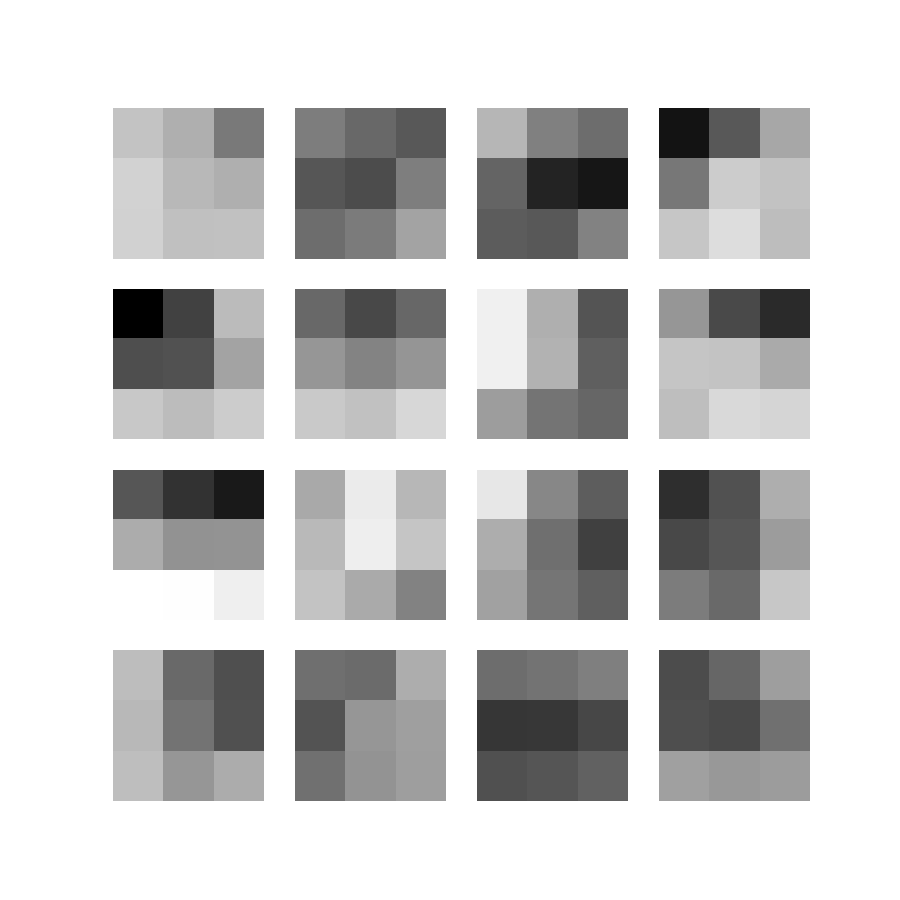

Row 3, column 1 resembles a horizontal edge, row 2, column 3 suggests a vertical edge, and row 4, column 3 shows a dark horizontal stripe. Row 1, column 4 and row 2, column 1 have corner-like contrasts, while several other tiles are uneven gradients with no clear interpretation; these small patterns do not establish that a kernel recognizes a particular digit.


### Convolution vs. Week 9

| Network | First-layer weights | Total weights | Final test accuracy |
|---|---:|---:|---:|
| Week 9 dense, 784 -> 100 -> 10 | 78,400 | 79,400 | 86.61% |
| Week 10 convolution, 16 shared 3 x 3 kernels | 144 | 108,304 | 86.37% |

Neither network uses biases: the convolution's classifier adds 10,816 x 10 = 108,160 weights, so its smaller first layer still gives a larger total network. Its test accuracy is 0.24 percentage points below Week 9's recorded result, but the architecture, batch size, dropout masks, and training rows differ, so one run cannot isolate weight sharing's effect on generalization.


## Part 5 - Tests

### Original source: `test_watchers.py`

The five original tests check patch shapes and contents, the hidden shape and tanh range, one kernel-gradient update, and short-run learning on validation data. We need these checks to catch geometry and gradient errors before trusting the training results; the learning test uses alpha 0.2 for 30 epochs and leaves the test set alone.


In [10]:
import numpy as np
import forms as av

from data import load_mnist, one_hot
from conv import get_patches, cnn_forward
from part3_train import train_step, cnn_full_train

rng = np.random.RandomState(0)

def test_patch_shape():
    test1, _ = get_patches(rng.randn(100, 28, 28))
    test2, _ = get_patches(rng.randn(1, 6, 6))
    test3, _ = get_patches(rng.randn(50, 256, 256))

    assert test1.shape == (67600, 9), f"Input shape (100, 28, 28) -- expected shape (67600, 9), got {test1.shape}"
    assert test2.shape == (16, 9), f"Input shape (1, 6, 6) -- expected (16, 9), got {test2.shape}"
    assert test3.shape == (254 * 254 * 50, 9), f"Input shape (50, 256, 256) -- expected (3225800, 9), got {test3.shape}"

def test_patch_contents():
    layer = rng.rand(10, 6, 6)
    patch = layer[0, :3, :3].flatten()
    patches, _ = get_patches(layer)
    first_patch = patches[0]
    assert np.all(a == b for a, b in zip(first_patch, patch)), f"First patch should be the top-left corner -- expected {patch}, got {first_patch}"

def test_forward_shape():
    # somehow get layer_1
    batches = np.array([14, 32, 128, 271])
    for batch in batches:
        layer_0 = rng.rand(batch, 28, 28)
        kernels, W_1_2 = 0.5 * rng.randn(9, 16), 0.05 * rng.randn(10816, 10)
        layer_1, _, _ = cnn_forward(layer_0, kernels, W_1_2)
        assert layer_1.shape == (batch, 10816), f"Layer 1's shape should be (batch, 10816), got {layer_1.shape}"
        assert np.all(np.min(layer_1) > -1 and np.max(layer_1) < 1), f"Tanh output should be in range (-1, 1), got min={np.min(layer_1)}, max={np.max(layer_1)}"

# NOTE: copied from assignment; may need tweaking later
def test_step():
    layer_0 = rng.rand(3, 28, 28)  # 3 tiny "images"
    kernels, W_1_2 = 0.5 * rng.randn(9, 16), 0.05 * rng.randn(10816, 10)
    Y = np.eye(10)[[3, 7, 1]]
    mask = rng.randint(2, size=(3, 10816))
    fp, es = get_patches(layer_0)
    ko = fp.dot(kernels)
    l1 = np.tanh(ko.reshape(layer_0.shape[0], 676 * 16))
    layer_2 = av.softmax((l1 * mask * 2).dot(W_1_2))
    delta_2 = (layer_2 - Y) / 3  # batch average: 3 images
    d1 = delta_2.dot(W_1_2.T) * (1 - l1 ** 2) * mask * 2
    expected = fp.T.dot(d1.reshape(ko.shape))  # (9, 16)
    got = train_step(layer_0, Y, kernels.copy(), W_1_2.copy(), mask, alpha=0.02)
    assert got.shape == (9, 16)
    # either backward-mask convention: mask * 2 (exact) or mask (Trask)
    assert np.allclose(got, expected) or np.allclose(got, expected / 2)

# NOTE: Anticipate signature and return value changes
def test_learn():
    (X_train, y_train), _ = load_mnist()
    X_val, y_val = X_train[1000:2000], one_hot(y_train[1000:2000])
    X_train, y_train = X_train[:1000], one_hot(y_train[:1000])
    _, _, val_acc = cnn_full_train(X_train, y_train, X_val, y_val,
                    alpha=0.2, epochs=30, batch_size=128, verbose=False)
    assert val_acc > 0.75, f"Final validation accuracy should be comfortably above chance, got {val_acc}"

# Copied from other tests
if __name__ == "__main__":
    tests = [name for name in dir() if name.startswith("test_")]
    for test_name in sorted(tests):
        test_func = globals()[test_name]
        try:
            test_func()
            print(f" PASS: {test_name}")
        except AssertionError as e:
            print(f" FAIL (AssertionError): {test_name} -- {e}")


### Run the checks

This cell runs the five original tests and adds deterministic patch ordering and an exact update check for both weight matrices, including a finite-difference kernel check with a fixed mask. The supplemental checks verify details beyond the original assertions without changing `test_watchers.py`, and the output reports all seven results.


In [11]:
def notebook_patch_order():
    images = np.arange(2 * 4 * 4).reshape(2, 4, 4)
    got, shape = get_patches(images)
    expected = np.array([
        images[image, row:row+3, col:col+3].ravel()
        for image in range(2) for row in range(2) for col in range(2)
    ])
    assert shape == (2, 4, 3, 3)
    assert np.array_equal(got, expected)

def notebook_backprop():
    local_rng = np.random.RandomState(0)
    images = local_rng.rand(3, 28, 28)
    a = 0.02 * local_rng.randn(9, 16)
    b = 0.01 * local_rng.randn(10816, 10)
    labels = np.eye(10)[[3, 7, 1]]
    mask = local_rng.randint(2, size=(3, 10816))
    patches, _ = get_patches(images)
    responses = patches @ a
    hidden = np.tanh(responses.reshape(3, 10816))
    dropped = hidden * mask * 2
    d2 = (softmax(dropped @ b) - labels) / 3
    d1 = (d2 @ b.T) * (1 - hidden**2) * mask * 2
    expected = patches.T @ d1.reshape(responses.shape)
    aa, bb = a.copy(), b.copy()
    got = train_step(images, labels, aa, bb, mask, 0.02)
    assert np.allclose(got, expected)
    assert np.allclose(aa, a - 0.02 * expected)
    assert np.allclose(bb, b - 0.02 * dropped.T @ d2)

    # Fix the mask so the numerical loss and analytic derivative agree.
    def loss(weights):
        h = np.tanh((patches @ weights).reshape(3, 10816)) * mask * 2
        logits = h @ b
        logits -= logits.max(axis=1, keepdims=True)
        log_probs = logits - np.log(np.exp(logits).sum(axis=1, keepdims=True))
        return -np.sum(labels * log_probs) / 3

    plus, minus = a.copy(), a.copy()
    step = 1e-5
    plus[2, 5] += step
    minus[2, 5] -= step
    numerical = (loss(plus) - loss(minus)) / (2 * step)
    assert np.isclose(got[2, 5], numerical, rtol=1e-5, atol=1e-7)
    # Verify evaluation batching, including a one-example remainder.
    assert np.isclose(
        notebook_evaluate(images, labels, a, b, eval_batch_size=2),
        _original_evaluate(images, labels, a, b),
    )

checks = [test_patch_shape, test_patch_contents, test_forward_shape,
          test_step, test_learn, notebook_patch_order, notebook_backprop]
test_results = {}
for check in checks:
    try:
        check()
        test_results[check.__name__] = True
        print("PASS:", check.__name__)
    except AssertionError as exc:
        test_results[check.__name__] = False
        print("FAIL:", check.__name__, str(exc))
print(f"{sum(test_results.values())}/{len(checks)} notebook checks passed")


PASS: test_patch_shape
PASS: test_patch_contents
PASS: test_forward_shape
PASS: test_step
PASS: test_learn
PASS: notebook_patch_order
PASS: notebook_backprop
7/7 notebook checks passed


## Submission notes

All six source cells match their Week 10 files exactly, and all code cells were executed sequentially in a fresh Python process with seven checks passing; interactive Jupyter Restart & Run All remains unverified. The source still needs the 104-image remainder batch, and the embedded `kernels.png` is the existing saved artifact rather than a plot regenerated from this measured run.


## Holocron — Reading

Our convolution reached 85.50% final validation accuracy and 86.37% test accuracy, compared with Week 9's dense network at 87.80% validation and 86.61% test. Weight sharing changes what the first layer must learn: sixteen 3 x 3 kernels use 144 weights instead of 78,400 separate pixel-to-hidden connections. The same filter reads every neighborhood, building in the assumption that a useful local pattern can appear anywhere in an image. That does not make the whole network shift-invariant, since the flattened classifier still distinguishes positions.

The saved kernel grid includes a horizontal transition at row 3, column 1 and a vertical transition at row 2, column 3, alongside less readable patterns. These suggest useful local contrasts, but they do not establish better generalization. The convolution has 108,304 total weights, versus 79,400 for the dense network. Its test result is 0.24 percentage points below Week 9's, and the original loop also leaves out 104 training images. One run under these differences cannot isolate weight sharing as the cause.

Korrith's warning concerns the purpose attached to that recognition. The same local features can help read handwriting or help a Watcher select someone to hunt. Engineering discipline means defining an acceptable purpose, collecting only the needed data with meaningful consent, testing who bears the errors, and making deployment decisions open to review. An accurate detector does not justify every use its designer can imagine.
